# Google Stock Price Forecasting: SimpleRNN vs LSTM vs Stacked LSTM

## Objective

Use the previous 60 trading observations of Google's opening stock price to predict the next trading observation.

We will compare three recurrent architectures:

1. **SimpleRNN** – a basic recurrent network with a hidden state.
2. **LSTM** – a recurrent network with input, forget and output gates, plus a cell state.
3. **Stacked LSTM** – two LSTM layers arranged one above the other.

All three models use the same input windows, chronological validation/test periods, optimizer, loss function and early-stopping policy.

> This is a sequence-modelling demonstration, not an investment or trading strategy. Stock prices are affected by many factors not represented in this univariate dataset. The experiment does not establish that any model can reliably predict future market prices.

## 1. Install and import dependencies

Install the libraries once in your environment if they are not already available.

```bash
pip install tensorflow pandas numpy matplotlib scikit-learn
```

The two CSV files should be placed in the same folder as this notebook:
- `Google_Stock_Price_Train.csv`
- `Google_Stock_Price_Test.csv`

The notebook expects an `Open` column in both files.

In [1]:
from pathlib import Path
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the Google stock data

We use the `Open` price as our single input feature and prediction target.

The original dataset is commonly distributed as two CSV files: one for the training period and one for the test period. Keep the chronological order intact.

In [ ]:
TRAIN_FILE = Path("data/Google_Stock_Price_Train.csv")
TEST_FILE = Path("data/Google_Stock_Price_Test.csv")

if not TRAIN_FILE.exists() or not TEST_FILE.exists():
    raise FileNotFoundError(
        "Place Google_Stock_Price_Train.csv and Google_Stock_Price_Test.csv "
        "in the same folder as this notebook, or update TRAIN_FILE and TEST_FILE."
    )

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

if "Open" not in train_df.columns or "Open" not in test_df.columns:
    raise ValueError("Both CSV files must contain an 'Open' column.")

train_values = train_df[["Open"]].astype("float32").values
test_values = test_df[["Open"]].astype("float32").values

print("Training rows:", len(train_values))
print("Test rows:", len(test_values))
train_df.head()

Training rows: 1258
Test rows: 20


,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"


## 3. Explore the training data

Plot the historical opening prices. Notice that the observations are ordered in time; shuffling them would destroy the sequence structure.

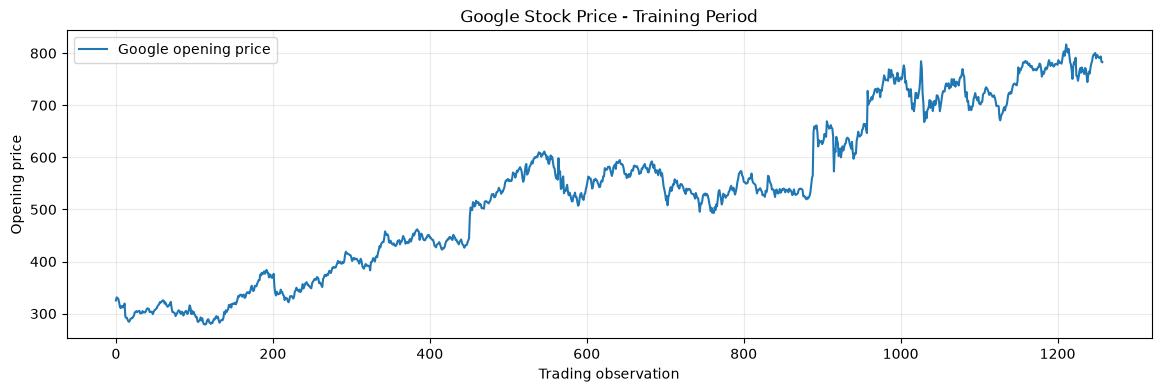

In [4]:
plt.figure(figsize=(14, 4))
plt.plot(train_values, label="Google opening price")
plt.title("Google Stock Price - Training Period")
plt.xlabel("Trading observation")
plt.ylabel("Opening price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. Create chronological training and validation periods

We reserve the final 20% of the supplied training period for validation.

- Earlier 80%: used to update model weights.
- Later 20%: used to monitor generalization and early stopping.
- Supplied test CSV: held back until final evaluation.

We do not randomly shuffle time-series observations.

In [18]:
TIMESTEPS = 160
VALIDATION_FRACTION = 0.20

split_index = int(len(train_values) * (1 - VALIDATION_FRACTION))

fit_raw = train_values[:split_index]
validation_raw = train_values[split_index:]

print("Model-fitting observations:", len(fit_raw))
print("Validation observations:", len(validation_raw))
print("Official test observations:", len(test_values))

Model-fitting observations: 1006
Validation observations: 252
Official test observations: 20


## 5. Scale the data without leaking future information

`MinMaxScaler` maps the training values into the range 0 to 1.

The scaler is fitted only on the model-fitting period. Validation and test data are transformed using those same fitted parameters. We must not fit a separate scaler on validation or test data.

In [19]:
scaler = MinMaxScaler(feature_range=(0, 1))

fit_scaled = scaler.fit_transform(fit_raw)
full_train_scaled = scaler.transform(train_values)
test_scaled = scaler.transform(test_values)

print("Scaled fitting range:", fit_scaled.min(), "to", fit_scaled.max())

Scaled fitting range: 0.0 to 1.0000001


## 6. Convert the series into 60-timestep windows

Each training example contains 60 consecutive observations, and its target is the immediately following observation.

For example:
- Input: trading observations 1–60; target: observation 61.
- Input: trading observations 2–61; target: observation 62.

Keras recurrent layers expect a three-dimensional input tensor:

`(samples, timesteps, features)`

Here, each sample has 60 time steps and one feature.

In [ ]:
# X_train = []
# y_train = []

# for i in range(60, 1258):
#     X_train.append(full_train_scaled[i-60:i, 0])
#     y_train.append(test_scaled[i, 0])

# X_train = np.array(X_train)
# y_train = np.array(y_train)

In [21]:
def create_sequences(data, timesteps):
    """Create overlapping sequences and the next value after each sequence."""
    X, y = [], []

    for end_index in range(timesteps, len(data)):
        X.append(data[end_index - timesteps:end_index, 0])
        y.append(data[end_index, 0])

    X = np.asarray(X, dtype="float32")
    y = np.asarray(y, dtype="float32")

    # Add the feature dimension:
    # (samples, timesteps) -> (samples, timesteps, 1)
    X = X.reshape((X.shape[0], X.shape[1], 1))
    return X, y


X_train, y_train = create_sequences(fit_scaled, TIMESTEPS)

# Validation windows include the 60 observations immediately before
# the first validation target. Those observations are available history.
validation_context = full_train_scaled[split_index - TIMESTEPS:]
X_val, y_val = create_sequences(validation_context, TIMESTEPS)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)

X_train: (846, 160, 1) y_train: (846,)
X_val:   (252, 160, 1) y_val:   (252,)


## 7. Inspect one sequence

The first input window contains 60 scaled prices. Its target is the next scaled price.

This is the exact pattern each recurrent model will learn.

First 60-step input window:
[0.093 0.105 0.102 0.099 0.086 0.07  0.063 0.071 0.066 0.072 0.066 0.081
 0.03  0.026 0.026 0.017 0.012 0.01  0.018 0.023 0.025 0.025 0.03  0.035
 0.047 0.048 0.052 0.048 0.05  0.051 0.053 0.043 0.045 0.044 0.052 0.047
 0.047 0.046 0.05  0.058 0.062 0.062 0.06  0.048 0.049 0.05  0.048 0.04
 0.048 0.055 0.056 0.061 0.063 0.071 0.074 0.078 0.086 0.085 0.087 0.092
 0.093 0.092 0.081 0.085 0.078 0.072 0.068 0.073 0.074 0.082 0.087 0.063
 0.048 0.048 0.045 0.044 0.033 0.038 0.044 0.051 0.055 0.053 0.044 0.041
 0.049 0.046 0.035 0.045 0.047 0.053 0.05  0.041 0.045 0.058 0.074 0.065
 0.04  0.053 0.041 0.049 0.041 0.036 0.028 0.028 0.011 0.01  0.015 0.016
 0.027 0.016 0.024 0.009 0.001 0.001 0.    0.002 0.013 0.019 0.02  0.008
 0.007 0.002 0.007 0.006 0.015 0.022 0.02  0.028 0.032 0.025 0.03  0.016
 0.007 0.012 0.016 0.018 0.017 0.026 0.048 0.04  0.055 0.048 0.055 0.059
 0.076 0.068 0.077 0.065 0.08  0.079 0.082 0.079 0.084 0.078 0.087 0.099
 0.11  0.107 0.114 0.115

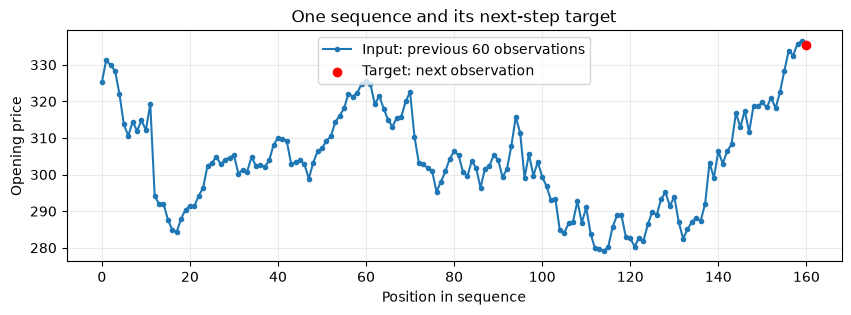

In [22]:
print("First 60-step input window:")
print(np.round(X_train[0, :, 0], 3))
print("Next-step target:", round(float(y_train[0]), 3))

first_window = scaler.inverse_transform(X_train[0, :, 0].reshape(-1, 1)).ravel()
first_target = scaler.inverse_transform([[y_train[0]]])[0, 0]

plt.figure(figsize=(10, 3))
plt.plot(range(TIMESTEPS), first_window, marker=".", label="Input: previous 60 observations")
plt.scatter([TIMESTEPS], [first_target], color="red", label="Target: next observation", zorder=3)
plt.xlabel("Position in sequence")
plt.ylabel("Opening price")
plt.title("One sequence and its next-step target")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. Define common model settings and early stopping

To make the comparison meaningful, all models use:
- The same sequence length.
- The same training and validation examples.
- The Adam optimizer.
- Mean squared error loss.
- The same batch size and maximum epoch count.
- The same early-stopping rule.

Early stopping monitors `val_loss`. If it does not improve for 10 epochs, training stops and the weights from the best validation epoch are restored.

In [23]:
UNITS = 50
BATCH_SIZE = 32
MAX_EPOCHS = 100
LEARNING_RATE = 0.001

def make_early_stopping():
    # Create a fresh callback for each model.
    return keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

def compile_regression_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mean_squared_error",
        metrics=["mae"]
    )
    return model

## 9. Model A – SimpleRNN

The SimpleRNN processes the 60 time steps sequentially and maintains a hidden state.

The final hidden representation is passed to a Dense layer that produces one next-step price prediction.

In [24]:
def build_simple_rnn():
    model = keras.Sequential([
        keras.layers.Input(shape=(TIMESTEPS, 1)),
        keras.layers.SimpleRNN(UNITS, activation="tanh"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1)
    ], name="SimpleRNN")

    return compile_regression_model(model)

rnn_model = build_simple_rnn()
rnn_model.summary()

Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Train SimpleRNN

We record training time and retain the training history so we can compare loss curves later.

In [25]:
start = time.perf_counter()

rnn_history = rnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    shuffle=False,
    verbose=1
)

rnn_training_seconds = time.perf_counter() - start
print(f"SimpleRNN training time: {rnn_training_seconds:.2f} seconds")

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0266 - mae: 0.1291 - val_loss: 0.0174 - val_mae: 0.1228
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0180 - mae: 0.1060 - val_loss: 0.0076 - val_mae: 0.0798
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0124 - mae: 0.0867 - val_loss: 0.0020 - val_mae: 0.0392
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0077 - mae: 0.0666 - val_loss: 0.0011 - val_mae: 0.0281
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0064 - mae: 0.0595 - val_loss: 8.6225e-04 - val_mae: 0.0216
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0058 - mae: 0.0559 - val_loss: 8.5266e-04 - val_mae: 0.0233
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0045 - mae: 0.0505 - val_loss: 7.5692e-04 - val_mae: 0.0211
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0041 - mae: 0.0492 - val_loss: 8.2937e-04 - val_mae: 0.0231
Epoch 9/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0

## 11. Model B – Standard LSTM

The standard LSTM has a hidden state and a cell state. Its gates regulate what information is forgotten, added to memory and exposed as output.

We use the same number of recurrent units as the SimpleRNN model.

In [ ]:
def build_lstm():
    model = keras.Sequential([
        keras.layers.Input(shape=(TIMESTEPS, 1)),
        keras.layers.LSTM(UNITS, activation="tanh"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1)
    ], name="LSTM")

    return compile_regression_model(model)

lstm_model = build_lstm()
lstm_model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Train the standard LSTM

In [27]:
start = time.perf_counter()

lstm_history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    shuffle=False,
    verbose=1
)

lstm_training_seconds = time.perf_counter() - start
print(f"LSTM training time: {lstm_training_seconds:.2f} seconds")

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - loss: 0.0266 - mae: 0.1419 - val_loss: 0.0234 - val_mae: 0.1457
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0092 - mae: 0.0780 - val_loss: 0.0020 - val_mae: 0.0382
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0075 - mae: 0.0695 - val_loss: 0.0019 - val_mae: 0.0325
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0049 - mae: 0.0537 - val_loss: 0.0028 - val_mae: 0.0413
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0042 - mae: 0.0473 - val_loss: 0.0025 - val_mae: 0.0383
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0036 - mae: 0.0442 - val_loss: 0.0036 - val_mae: 0.0485
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0038 - mae: 0.0456 - val_loss: 0.0017 - val_mae: 0.0306
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0033 - mae: 0.0429 - val_loss: 0.0013 - val_mae: 0.0286
Epoch 9/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - lo

## 13. Model C – Stacked LSTM

A stacked LSTM contains multiple LSTM layers.

The first LSTM must return its output at every time step because the second LSTM needs the entire output sequence.

- First LSTM output: `(batch, 60, 50)`.
- Second LSTM output by default: `(batch, 50)`.
- Dense output: `(batch, 1)`.

The second layer receives a sequence of learned representations rather than the original single-feature sequence.

In [ ]:
def build_stacked_lstm():
    model = keras.Sequential([
        keras.layers.Input(shape=(TIMESTEPS, 1)),

        # Return the full sequence so that the next LSTM layer
        # receives one representation for every input time step.
        keras.layers.LSTM(UNITS, return_sequences=True),
        keras.layers.Dropout(0.2),

        # The final LSTM returns only its final hidden representation.
        keras.layers.LSTM(UNITS),
        keras.layers.Dropout(0.2),

        keras.layers.Dense(1)
    ], name="Stacked_LSTM")

    return compile_regression_model(model)

stacked_lstm_model = build_stacked_lstm()
stacked_lstm_model.summary()

Model: "Stacked_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 160, 50)        │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 160, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

## 14. Train the Stacked LSTM

In [29]:
start = time.perf_counter()

stacked_lstm_history = stacked_lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[make_early_stopping()],
    shuffle=False,
    verbose=1
)

stacked_lstm_training_seconds = time.perf_counter() - start
print(f"Stacked LSTM training time: {stacked_lstm_training_seconds:.2f} seconds")

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - loss: 0.0105 - mae: 0.0835 - val_loss: 0.0126 - val_mae: 0.1032
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - loss: 0.0139 - mae: 0.0985 - val_loss: 0.0040 - val_mae: 0.0550
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - loss: 0.0064 - mae: 0.0632 - val_loss: 0.0024 - val_mae: 0.0373
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0069 - mae: 0.0678 - val_loss: 0.0029 - val_mae: 0.0461
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0091 - mae: 0.0812 - val_loss: 0.0037 - val_mae: 0.0532
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 0.0052 - mae: 0.0588 - val_loss: 0.0016 - val_mae: 0.0296
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0039 - mae: 0.0464 - val_loss: 0.0028 - val_mae: 0.0412
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.0052 - mae: 0.0579 - val_loss: 0.0015 - val_mae: 0.0307
Epoch 9/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - lo

## 15. Compare training and validation loss

Training loss measures fit on the observations used to update weights. Validation loss measures performance on the later observations reserved for model selection.

A widening gap between training and validation loss can indicate overfitting.

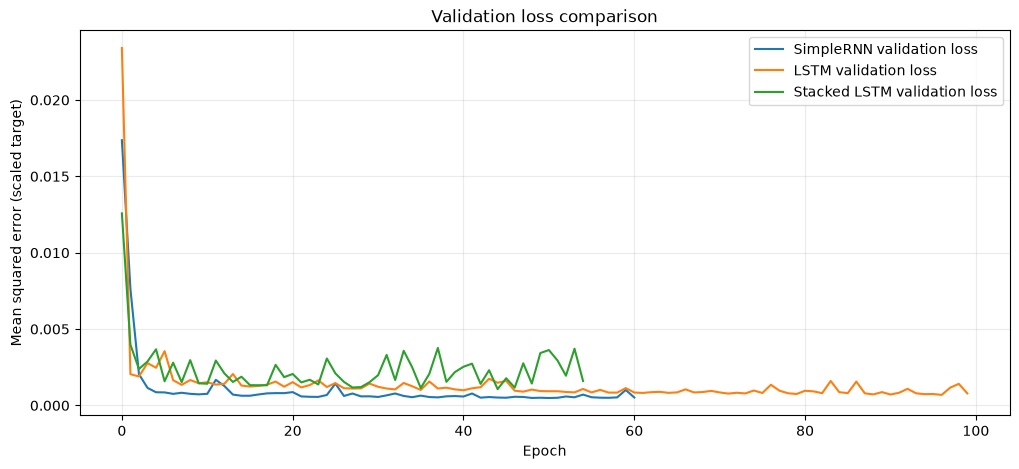

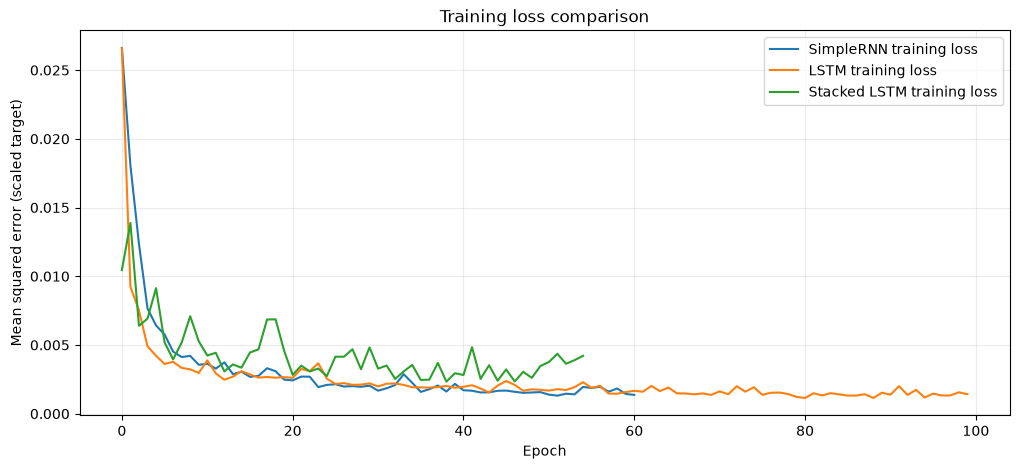

In [30]:
histories = {
    "SimpleRNN": rnn_history,
    "LSTM": lstm_history,
    "Stacked LSTM": stacked_lstm_history
}

plt.figure(figsize=(12, 5))
for name, history in histories.items():
    plt.plot(history.history["val_loss"], label=f"{name} validation loss")

plt.title("Validation loss comparison")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (scaled target)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(12, 5))
for name, history in histories.items():
    plt.plot(history.history["loss"], label=f"{name} training loss")

plt.title("Training loss comparison")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (scaled target)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 16. Prepare the official test sequences

To predict the first test observation, each model needs the 60 observations immediately before it. These are taken from the end of the supplied training data.

The test windows then move forward one observation at a time. Each test prediction uses the preceding observed prices, making this a one-step-ahead evaluation rather than a recursively generated multi-day forecast.

In [31]:
test_context = np.concatenate(
    [full_train_scaled[-TIMESTEPS:], test_scaled],
    axis=0
)

X_test, y_test_scaled = create_sequences(test_context, TIMESTEPS)

print("X_test shape:", X_test.shape)
print("Number of test targets:", len(y_test_scaled))
print("Number of actual test observations:", len(test_values))

assert len(X_test) == len(test_values)

X_test shape: (20, 160, 1)
Number of test targets: 20
Number of actual test observations: 20


## 17. Generate predictions from all three models

Each model predicts a scaled value. We reverse the scaling so that predictions can be compared with actual prices in the original units.

In [32]:
rnn_pred_scaled = rnn_model.predict(X_test, verbose=0)
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)
stacked_pred_scaled = stacked_lstm_model.predict(X_test, verbose=0)

rnn_predictions = scaler.inverse_transform(rnn_pred_scaled)
lstm_predictions = scaler.inverse_transform(lstm_pred_scaled)
stacked_lstm_predictions = scaler.inverse_transform(stacked_pred_scaled)

actual_prices = test_values.copy()

print("Prediction shape:", rnn_predictions.shape)
print("Actual shape:", actual_prices.shape)

Prediction shape: (20, 1)
Actual shape: (20, 1)


## 18. Evaluate all models using MAE and RMSE

- **MAE:** average absolute difference between actual and predicted prices.
- **RMSE:** square root of mean squared error; larger errors receive a stronger penalty.

These metrics are calculated on the same untouched test observations.

In [ ]:
def regression_metrics(actual, predicted, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

metrics_table = pd.DataFrame([
    regression_metrics(actual_prices, rnn_predictions, "SimpleRNN"),
    regression_metrics(actual_prices, lstm_predictions, "LSTM"),
    regression_metrics(actual_prices, stacked_lstm_predictions, "Stacked LSTM")
])

training_times = {
    "SimpleRNN": rnn_training_seconds,
    "LSTM": lstm_training_seconds,
    "Stacked LSTM": stacked_lstm_training_seconds
}
metrics_table["Training time (seconds)"] = metrics_table["Model"].map(training_times)

metrics_table.sort_values("RMSE")

,Model,MAE,RMSE,Training time (seconds)
0,SimpleRNN,7.426856,10.119878,25.214517
1,LSTM,10.211261,13.138053,104.383473
2,Stacked LSTM,18.458963,20.775559,124.493995


## 19. Plot actual versus predicted stock prices

This plot overlays the actual test-period prices with predictions from all three architectures.

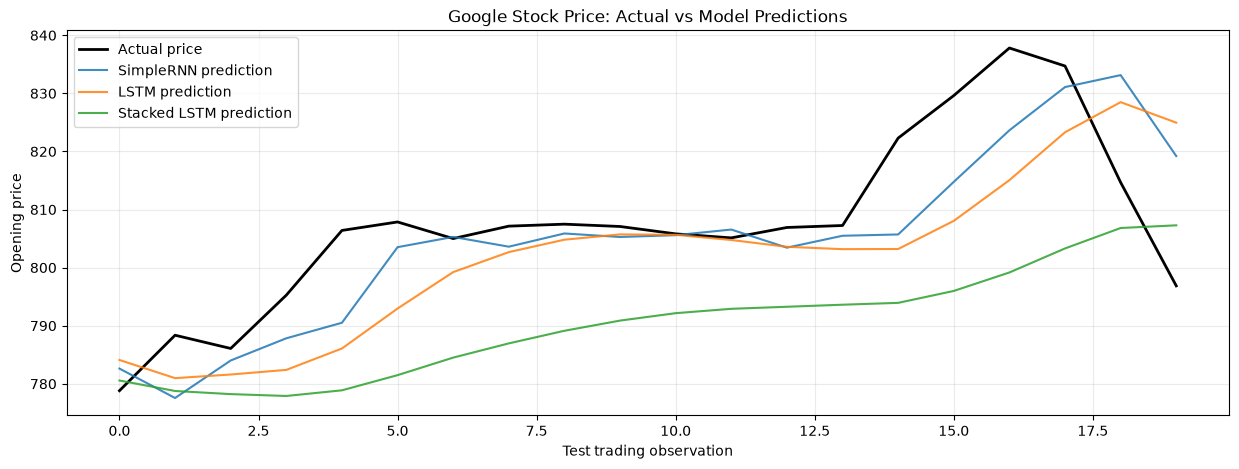

In [34]:
plt.figure(figsize=(15, 5))
plt.plot(actual_prices, color="black", label="Actual price", linewidth=2)
plt.plot(rnn_predictions, label="SimpleRNN prediction", alpha=0.85)
plt.plot(lstm_predictions, label="LSTM prediction", alpha=0.85)
plt.plot(stacked_lstm_predictions, label="Stacked LSTM prediction", alpha=0.85)
plt.title("Google Stock Price: Actual vs Model Predictions")
plt.xlabel("Test trading observation")
plt.ylabel("Opening price")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 20. Compare absolute prediction errors

Absolute error shows how far each prediction was from the corresponding actual price, without considering whether the model overpredicted or underpredicted.

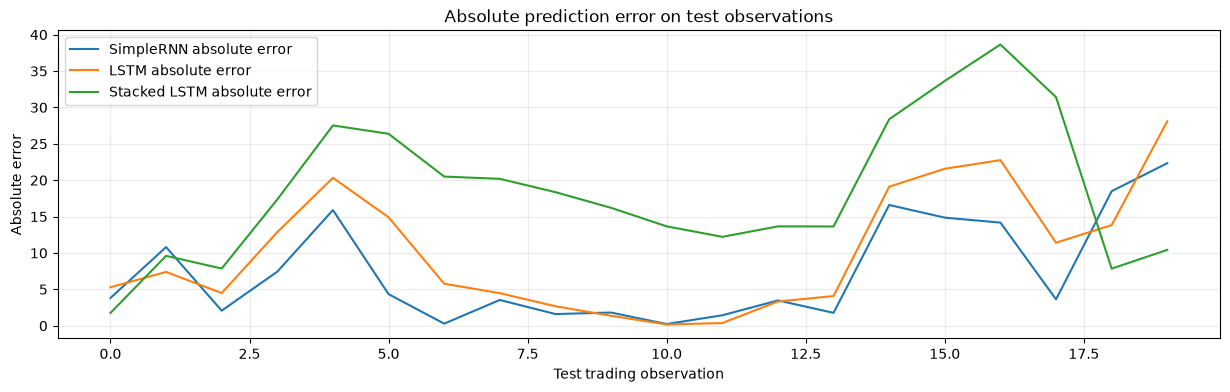

In [35]:
rnn_error = np.abs(actual_prices.ravel() - rnn_predictions.ravel())
lstm_error = np.abs(actual_prices.ravel() - lstm_predictions.ravel())
stacked_error = np.abs(actual_prices.ravel() - stacked_lstm_predictions.ravel())

plt.figure(figsize=(15, 4))
plt.plot(rnn_error, label="SimpleRNN absolute error")
plt.plot(lstm_error, label="LSTM absolute error")
plt.plot(stacked_error, label="Stacked LSTM absolute error")
plt.title("Absolute prediction error on test observations")
plt.xlabel("Test trading observation")
plt.ylabel("Absolute error")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 21. Forecast the next observation after the supplied dataset

For this final demonstration, we take the latest 60 available observations from the combined training and test files.

The resulting forecasts refer to the next trading observation after the final row in the supplied data. There is no actual target in these files against which to evaluate this final forecast.

In [ ]:
all_available_scaled = np.concatenate(
    [full_train_scaled, test_scaled],
    axis=0
)

latest_window = all_available_scaled[-TIMESTEPS:]
latest_window = latest_window.reshape(1, TIMESTEPS, 1)

next_rnn_scaled = rnn_model.predict(latest_window, verbose=0)
next_lstm_scaled = lstm_model.predict(latest_window, verbose=0)
next_stacked_scaled = stacked_lstm_model.predict(latest_window, verbose=0)

next_forecasts = pd.DataFrame({
    "Model": ["SimpleRNN", "LSTM", "Stacked LSTM"],
    "Next observation forecast": [
        scaler.inverse_transform(next_rnn_scaled)[0, 0],
        scaler.inverse_transform(next_lstm_scaled)[0, 0],
        scaler.inverse_transform(next_stacked_scaled)[0, 0]
    ]
})

next_forecasts

## 22. Final comparison and interpretation

Use the measured results rather than assuming that the more complex architecture must win.

Questions to consider:
1. Which model has the lowest test MAE?
2. Which model has the lowest test RMSE?
3. Did the stacked LSTM improve on the single-layer LSTM?
4. Which model trained fastest?
5. Do the prediction curves follow the actual series closely?
6. Is there evidence of overfitting in the training/validation curves?
7. What information is missing from a model that uses only historical opening prices?

### Important limitations

- The dataset is univariate: only the opening price is used.
- No news, market index, volume, technical indicators or macroeconomic variables are included.
- The test period is limited.
- The test evaluation is one-step-ahead with actual preceding observations supplied at each step.
- This is not a validated trading system.

A real forecasting project should also compare against simple baselines, use walk-forward validation, consider multiple features and evaluate stability across different market periods.